# Dataset Selection and Final Project Planning Lab
**Predicting Retrieval Failure in Consumer Health Question Answering**

Jeremy Childress

## 1. Data Selection

**Dataset:** MedQuAD (Medical Question Answering Dataset)

**Source:** https://github.com/abachaa/MedQuAD (also on Hugging Face at https://huggingface.co/datasets/lavita/MedQuAD)

MedQuAD is a set of consumer health questions paired with answers from NIH websites such as cancer.gov, GARD, and MedlinePlus. It was built by researchers at the National Library of Medicine and is released under a CC BY 4.0 license.

**Why I selected it.** Many AI tools answer health questions by first searching a set of documents for relevant passages. If the search returns the wrong passage, the tool can still give a confident but wrong answer. I want to predict when that search step fails. This also builds toward my capstone, where I plan to study retrieval for questions about AI and cybersecurity policy in health systems.

**Note on requirements.** MedQuAD is not on the UCI repository, and it does not come with a binary outcome. I create the binary target myself by running a search method on each question and checking whether the correct answer comes back (Section 5). I am requesting an exception to use it. If it is not approved, my backup is the UCI Phishing Websites dataset (https://archive.ics.uci.edu/dataset/327/phishing+websites).

**Requirements check**

| Requirement | MedQuAD |
|---|---|
| Binary classification | Yes, `retrieval_success` (1 = correct answer in top 10, 0 = not) |
| At least 300 observations | Yes, 15,848 answered questions. I use a sample of 2,000 here. |
| At least 10 predictors | Yes, 10 planned predictors (Section 6) |

## 2. Import the Data

In [1]:
!pip install -q rank_bm25
!git clone -q --depth 1 https://github.com/abachaa/MedQuAD.git

In [2]:
import glob, re
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rank_bm25 import BM25Okapi

rows = []
for f in sorted(glob.glob('MedQuAD/*_QA/*.xml')):
    doc = ET.parse(f).getroot()
    for qa in doc.iter('QAPair'):
        q, a = qa.find('Question'), qa.find('Answer')
        rows.append({
            'source': doc.get('source'),
            'doc_id': doc.get('id'),
            'focus': (doc.findtext('Focus') or '').strip(),
            'qtype': q.get('qtype'),
            'question': (q.text or '').strip(),
            'answer': (a.text or '').strip() if a is not None else '',
        })

df = pd.DataFrame(rows)
df.head()

,source,doc_id,focus,qtype,question,answer
0,ADAM,0000001,A guide to clinical trials for cancer,information,What is (are) A guide to clinical trials for c...,
1,ADAM,0000001,A guide to clinical trials for cancer,research,what research (or clinical trials) is being do...,
2,ADAM,0000001,A guide to clinical trials for cancer,research,what research (or clinical trials) is being do...,
3,ADAM,0000001,A guide to clinical trials for cancer,research,what research (or clinical trials) is being do...,
4,ADAM,0000001,A guide to clinical trials for cancer,research,what research (or clinical trials) is being do...,


## 3. Dataset Structure

In [3]:
print(df.shape)
df.info()

(46882, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46882 entries, 0 to 46881
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   source    46882 non-null  object
 1   doc_id    46877 non-null  object
 2   focus     46882 non-null  object
 3   qtype     46882 non-null  object
 4   question  46882 non-null  object
 5   answer    46882 non-null  object
dtypes: object(6)
memory usage: 2.1+ MB


Each row is one question with its answer. The columns are the NIH source website, the document ID (one NIH page), the focus (the disease or topic), the question type, the question text, and the answer text.

## 4. Data Quality

In [4]:
df['has_answer'] = df['answer'].str.len() > 0
df.groupby('source')['has_answer'].agg(['count', 'sum']).rename(columns={'count': 'questions', 'sum': 'answered'})

,questions,answered
source,,
ADAM,17348,0
CDC,270,270
CancerGov,729,729
GARD,5394,5389
GHR,5430,5430
MPlusDrugs,12889,0
MPlusHealthTopics,981,981
MPlusHerbsSupplements,792,0
NIDDK,1192,1192


Three MedlinePlus subsets (ADAM, MPlusDrugs, MPlusHerbsSupplements) have no answers because they were removed for copyright reasons. These questions cannot be used, so I drop them.

In [5]:
data = df[df['has_answer']].copy()
print('Answered questions:', len(data))
print('Duplicate question text:', data['question'].duplicated().sum())
print('Duplicate answer text:', data['answer'].duplicated().sum())
print('Share of questions starting with "What is (are)":', round(data['question'].str.startswith('What is (are)').mean(), 3))

Answered questions: 15848
Duplicate question text: 1339
Duplicate answer text: 590
Share of questions starting with "What is (are)": 0.262


**Issues found**
- **Missing answers.** About two thirds of the raw questions have no answer. These are removed.
- **Duplicate questions.** Some question text appears more than once with different answers, for example the same disease covered by two NIH sites. That makes the correct answer ambiguous, so I keep only questions that appear once.
- **Duplicate answers.** Some answers are identical across questions. I search over unique passages so a duplicate is not counted as a miss.
- **Templated wording.** Many questions follow fixed templates like "What is (are) X ?", so they are cleaner than real patient questions.

In [6]:
data = data[~data['question'].duplicated(keep=False)].copy()
data['q_words'] = data['question'].str.split().str.len()
data['a_words'] = data['answer'].str.split().str.len()
data['focus_words'] = data['focus'].str.split().str.len()
print('Questions after cleaning:', len(data))
data[['q_words', 'a_words', 'focus_words']].describe().round(1)

Questions after cleaning: 13675


,q_words,a_words,focus_words
count,13675.0,13675.0,13675.0
mean,8.4,186.5,3.0
std,2.3,228.5,1.6
min,3.0,1.0,0.0
25%,7.0,67.0,2.0
50%,8.0,131.0,3.0
75%,10.0,246.0,4.0
max,27.0,3708.0,17.0


In [7]:
data['qtype'].value_counts().head(10)

,count
qtype,
information,3414
symptoms,2566
treatment,2015
inheritance,1318
frequency,1120
genetic changes,1087
causes,545
exams and tests,507
research,355


## 5. Create the Target Variable

MedQuAD does not include a binary outcome, so I create one. I index all unique answer passages with BM25, a keyword search method. For a sample of 2,000 questions, I search each question and check whether its correct answer is in the top 10 results. In the final project I will repeat this for three more search methods (embedding search, hybrid, and hybrid with reranking).

In [8]:
def tok(s):
    return re.findall(r'[a-z0-9]+', s.lower())

passages = data['answer'].drop_duplicates().reset_index(drop=True)
passage_id = {text: i for i, text in enumerate(passages)}
passage_doc = data.drop_duplicates('answer').set_index('answer')['doc_id']
doc_of = passages.map(passage_doc).values
data['pid'] = data['answer'].map(passage_id)

bm25 = BM25Okapi([tok(p) for p in passages])
print('Passages indexed:', len(passages))

Passages indexed: 13169


In [9]:
sample = data.sample(2000, random_state=42).copy()
results = []
for q, pid in zip(sample['question'], sample['pid']):
    words = tok(q)
    scores = bm25.get_scores(words)
    top10 = np.argsort(-scores)[:10]
    idf = [bm25.idf[w] for w in words if w in bm25.idf]
    results.append({
        'retrieval_success': int(pid in top10),
        'top_score': scores[top10[0]],
        'score_gap': scores[top10[0]] - scores[top10[4]],
        'same_page_top10': int((doc_of[top10] == doc_of[top10[0]]).sum()),
        'mean_idf': np.mean(idf) if idf else 0,
        'max_idf': np.max(idf) if idf else 0,
    })

sample = pd.concat([sample.reset_index(drop=True), pd.DataFrame(results)], axis=1)
sample['method'] = 'bm25'
sample['retrieval_success'].value_counts(normalize=True).round(3)

,proportion
retrieval_success,
1,0.814
0,0.186


About 81% of BM25 searches succeed and 19% fail. Failure is the minority class but common enough to model.

## 6. Predictor Variables

| Predictor | Type | Description |
|---|---|---|
| `q_words` | Numeric | Number of words in the question |
| `mean_idf` | Numeric | Average rarity of the question's words |
| `max_idf` | Numeric | Rarity of the question's rarest word |
| `focus_words` | Numeric | Length of the topic name (disease or condition) |
| `qtype` | Categorical | Question type, such as treatment or symptoms |
| `source` | Categorical | NIH website the answer came from |
| `method` | Categorical | Search method (only BM25 so far, four in the final project) |
| `top_score` | Numeric | Score of the top search result |
| `score_gap` | Numeric | Gap between the 1st and 5th result scores |
| `same_page_top10` | Numeric | How many top 10 results come from the same NIH page as the top result |

None of these use the correct answer, so there is no target leakage.

In [10]:
predictors = ['q_words', 'mean_idf', 'max_idf', 'focus_words', 'top_score', 'score_gap', 'same_page_top10']
sample.groupby('retrieval_success')[predictors].mean().round(2).T

retrieval_success,0,1
q_words,9.12,8.31
mean_idf,2.97,2.94
max_idf,6.45,6.88
focus_words,3.43,2.94
top_score,33.74,33.63
score_gap,7.96,9.13
same_page_top10,2.43,3.30


## 7. Exploratory Visualizations

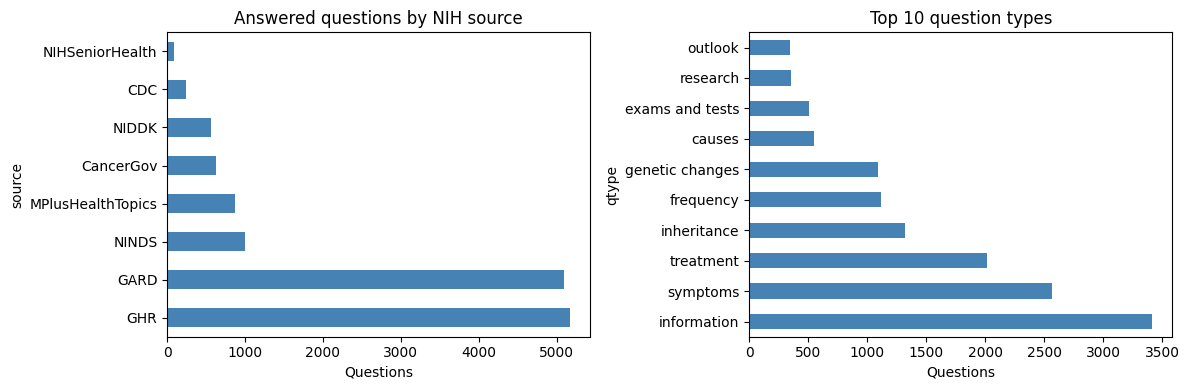

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data['source'].value_counts().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Answered questions by NIH source')
axes[0].set_xlabel('Questions')

data['qtype'].value_counts().head(10).plot.barh(ax=axes[1], color='steelblue')
axes[1].set_title('Top 10 question types')
axes[1].set_xlabel('Questions')

plt.tight_layout()
plt.show()

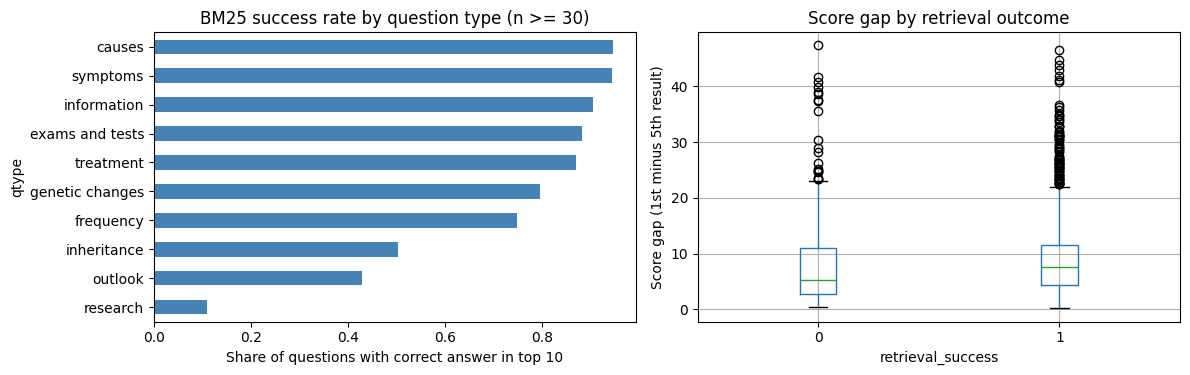

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rate = sample.groupby('qtype')['retrieval_success'].agg(['mean', 'count'])
rate = rate[rate['count'] >= 30].sort_values('mean')
rate['mean'].plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('BM25 success rate by question type (n >= 30)')
axes[0].set_xlabel('Share of questions with correct answer in top 10')

sample.boxplot(column='score_gap', by='retrieval_success', ax=axes[1])
axes[1].set_title('Score gap by retrieval outcome')
axes[1].set_xlabel('retrieval_success')
axes[1].set_ylabel('Score gap (1st minus 5th result)')
plt.suptitle('')

plt.tight_layout()
plt.show()

**What I see**
- The data is dominated by a few NIH sources, mainly GHR and GARD, so results may not generalize evenly across topics.
- Success rates differ a lot by question type. Questions about causes and symptoms succeed over 90% of the time, while research, outlook, and inheritance questions succeed about half the time or less. Question type will likely be a strong predictor.
- Failed searches tend to have smaller score gaps, meaning the search engine was less sure of its top result. That is a signal I can use without knowing the answer.
- In the table in Section 6, failed searches also have fewer top 10 results from the same NIH page, so the search drifted away from the right topic.

## 8. Anticipated Preprocessing
- Drop questions with no answer (the three copyright-removed MedlinePlus subsets).
- Drop duplicated questions with ambiguous answers.
- Search over unique passages so duplicate answers are not counted as misses.
- One-hot encode categorical predictors (`qtype`, `source`, `method`) and group rare question types into "other".
- Scale numeric predictors for logistic regression.
- Use 5-fold cross-validation grouped by question, since each question will appear once per search method in the final dataset.

## 9. Potential Challenges
- **Derived target.** The label depends on which search methods I run, so results describe those methods, not search in general.
- **Templated questions.** Questions are cleaner than real patient questions, which may overstate how well search works.
- **Uneven sources.** A few NIH sites make up most of the data.
- **Class balance.** Failure is the minority class, so accuracy alone would be misleading.
- **Compute.** Embedding search and reranking are slower than BM25, so I will keep the 2,000-question sample.

## 10. Project Plan
- **Prediction problem.** Given a consumer health question and a search method, predict whether the method fails to return the correct answer in its top 10 results.
- **Target variable.** `retrieval_success` (1 = correct answer in top 10, 0 = not). With 2,000 questions and 4 search methods, the final dataset will have about 8,000 rows.
- **Evaluation metric.** ROC-AUC as the main metric, with PR-AUC as a second metric because failure is the minority class.
- **Models.** Logistic regression as a baseline, compared with gradient-boosted trees.